# PBL JS13 - ANN (MLP) dan Evaluasi Classifier

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier)

Notebook ini menerapkan langkah-langkah jobsheet JS13 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS13 | Penerapan pada URL |
| --- | --- |
| Teori evaluasi classifier: confusion matrix, accuracy, precision, recall, F1, ROC/AUC | Evaluasi lengkap multikelas dan biner (aman vs berbahaya) |
| Praktikum 2 - Keras Sequential klasifikasi | MLP pada 28 fitur leksikal, softmax 7 kelas |
| Tugas 2/3 dan Tugas Praktikum - jumlah neuron, hidden layer, Sigmoid vs ReLU, waktu | Eksperimen arsitektur dan aktivasi |
| (tambahan) Data tidak seimbang | Perbandingan dengan `class_weight` |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


In [2]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
                             precision_score, recall_score)
tf.keras.utils.set_random_seed(42)
df = pbl_url.load_urls()
X = np.log1p(pbl_url.lexical_features(df['url']).clip(lower=0)).to_numpy(np.float32)
le = LabelEncoder().fit(pbl_url.CLASSES); y = le.transform(df['type'])
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.1, stratify=y_tmp, random_state=42)
scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te)
print(X_tr.shape, X_va.shape, X_te.shape, dict(zip(le.classes_, range(len(le.classes_)))))

(564267, 28) (62697, 28) (156741, 28) {np.str_('Exploit'): 0, np.str_('benign'): 1, np.str_('defacement'): 2, np.str_('legitimate'): 3, np.str_('malware'): 4, np.str_('phishing'): 5, np.str_('spam'): 6}


## Model dasar: Dense 128-64 ReLU, softmax 7 kelas (pola Praktikum 2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,423 (48.53 KB)

 Trainable params: 12,423 (48.53 KB)

 Non-trainable params: 0 (0.00 B)

Waktu latih 9 s | test acc=0.8085, macro-F1=0.6119


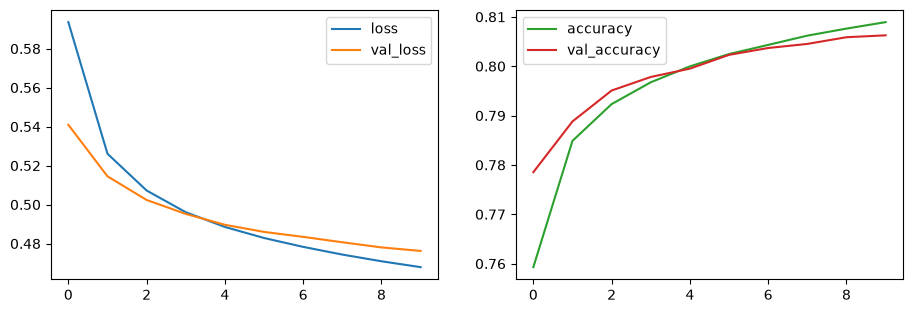

In [3]:
def build(hidden=(128, 64), activation='relu'):
    return tf.keras.Sequential([tf.keras.layers.Input(shape=(X_tr.shape[1],))]
                               + [tf.keras.layers.Dense(h, activation=activation) for h in hidden]
                               + [tf.keras.layers.Dense(len(le.classes_), activation='softmax')])
def train(model, epochs=10, class_weight=None):
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.perf_counter()
    h = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=256, verbose=0, class_weight=class_weight)
    return h, time.perf_counter() - t0
model = build(); model.summary()
history, dur = train(model)
proba = model.predict(X_te, verbose=0, batch_size=4096); pred = proba.argmax(1)
print(f'Waktu latih {dur:.0f} s | test acc={accuracy_score(y_te, pred):.4f}, macro-F1={f1_score(y_te, pred, average="macro"):.4f}')
pd.DataFrame(history.history)[['loss', 'val_loss', 'accuracy', 'val_accuracy']].plot(subplots=[('loss', 'val_loss'), ('accuracy', 'val_accuracy')], figsize=(11, 3.5), layout=(1, 2)); plt.show()

## Evaluasi classifier (materi JS13 bagian 1)

              precision    recall  f1-score   support

     Exploit     1.0000    0.3673    0.5373        49
      benign     0.8261    0.8683    0.8467     85286
  defacement     0.8863    0.7902    0.8355     19053
  legitimate     0.4713    0.0353    0.0657      1162
     malware     0.9492    0.8080    0.8729      4718
    phishing     0.7331    0.7317    0.7324     45923
        spam     0.8797    0.2527    0.3927       550

    accuracy                         0.8085    156741
   macro avg     0.8208    0.5505    0.6119    156741
weighted avg     0.8075    0.8085    0.8051    156741



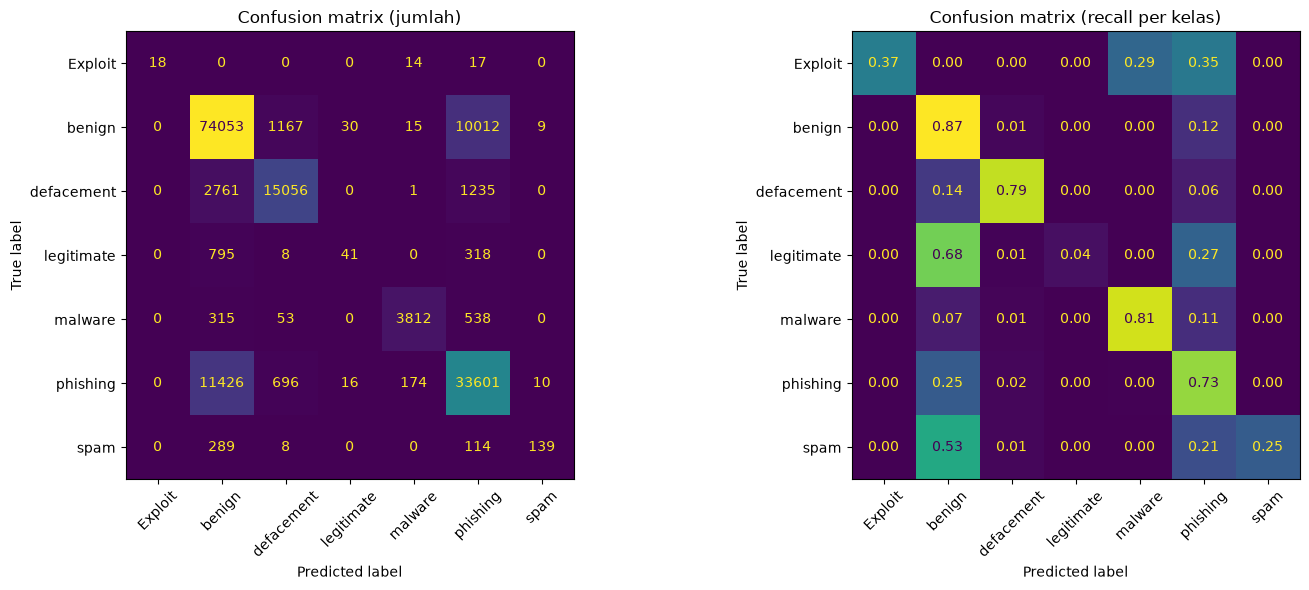

ROC-AUC one-vs-rest macro: 0.9506


In [4]:
print(classification_report(y_te, pred, target_names=le.classes_, digits=4, zero_division=0))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=le.classes_, ax=ax[0], colorbar=False, xticks_rotation=45, values_format='d')
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=le.classes_, normalize='true', values_format='.2f', ax=ax[1], colorbar=False, xticks_rotation=45)
ax[0].set_title('Confusion matrix (jumlah)'); ax[1].set_title('Confusion matrix (recall per kelas)'); plt.tight_layout(); plt.show()
print('ROC-AUC one-vs-rest macro:', round(roc_auc_score(y_te, proba, multi_class='ovr', average='macro'), 4))

Biner aman vs berbahaya: TP=56597 TN=74087 FP=12361 FN=13696
accuracy=0.8338 precision=0.8207 recall=0.8052 F1=0.8129 ROC-AUC=0.9182 FPR=0.1430


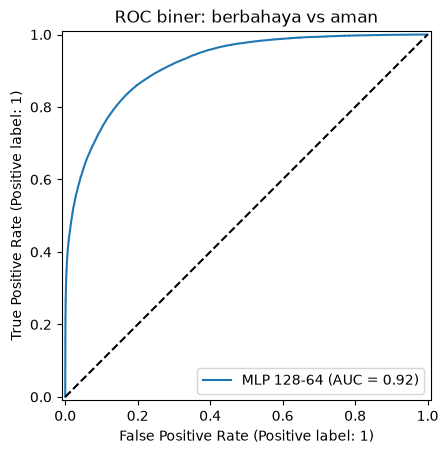

In [5]:
benign_idx = [list(le.classes_).index(c) for c in pbl_url.BENIGN_CLASSES]
yb_true = (~np.isin(y_te, benign_idx)).astype(int)
p_mal = 1 - proba[:, benign_idx].sum(1)
yb_pred = (p_mal > 0.5).astype(int)
tn, fp, fn, tp = pd.crosstab(yb_true, yb_pred).to_numpy().ravel()
print(f'Biner aman vs berbahaya: TP={tp} TN={tn} FP={fp} FN={fn}')
print(f'accuracy={accuracy_score(yb_true, yb_pred):.4f} precision={precision_score(yb_true, yb_pred):.4f} recall={recall_score(yb_true, yb_pred):.4f} '
      f'F1={f1_score(yb_true, yb_pred):.4f} ROC-AUC={roc_auc_score(yb_true, p_mal):.4f} FPR={fp / (fp + tn):.4f}')
RocCurveDisplay.from_predictions(yb_true, p_mal, name='MLP 128-64'); plt.plot([0, 1], [0, 1], 'k--'); plt.title('ROC biner: berbahaya vs aman'); plt.show()

## Eksperimen arsitektur dan aktivasi (Tugas 2, Tugas 3, Tugas Praktikum)

In [6]:
from sklearn.utils.class_weight import compute_class_weight
cw = dict(enumerate(compute_class_weight('balanced', classes=np.arange(len(le.classes_)), y=y_tr)))
experiments = {
    'A. 128-64 ReLU (dasar)': dict(hidden=(128, 64)),
    'B. 32-16 ReLU': dict(hidden=(32, 16)),
    'C. 256-128 ReLU': dict(hidden=(256, 128)),
    'D. 256-128-64 ReLU (+1 layer)': dict(hidden=(256, 128, 64)),
    'E. 128-64 Sigmoid': dict(hidden=(128, 64), activation='sigmoid'),
    'F. 128-64 ReLU + class_weight balanced': dict(hidden=(128, 64), cw=True),
}
rows = []
for name, kw in experiments.items():
    tf.keras.utils.set_random_seed(42)
    m = build(kw.get('hidden'), kw.get('activation', 'relu'))
    h, dur = train(m, class_weight=cw if kw.get('cw') else None)
    p_ = m.predict(X_te, verbose=0, batch_size=4096).argmax(1)
    rec = recall_score(y_te, p_, average=None)
    rows.append({'model': name, 'parameter': m.count_params(), 'val_acc': h.history['val_accuracy'][-1], 'test_acc': accuracy_score(y_te, p_),
                 'test_macro_F1': f1_score(y_te, p_, average='macro'), 'recall_Exploit': rec[list(le.classes_).index('Exploit')],
                 'recall_spam': rec[list(le.classes_).index('spam')], 'waktu_latih_s': dur})
exp = pd.DataFrame(rows).set_index('model'); exp.round(4)

,parameter,val_acc,test_acc,test_macro_F1,recall_Exploit,recall_spam,waktu_latih_s
model,,,,,,,
A. 128-64 ReLU (dasar),12423,0.8063,0.8085,0.6119,0.3673,0.2527,8.9409
B. 32-16 ReLU,1575,0.7800,0.7809,0.4841,0.1633,0.0000,6.3333
C. 256-128 ReLU,41223,0.8158,0.8178,0.6413,0.4286,0.3364,12.4698
D. 256-128-64 ReLU (+1 layer),49031,0.8165,0.8195,0.6364,0.4082,0.3345,14.4218
E. 128-64 Sigmoid,12423,0.7897,0.7907,0.4690,0.0204,0.0000,9.7039
F. 128-64 ReLU + class_weight balanced,12423,0.6044,0.6083,0.4167,0.9388,0.7709,9.1829


## Analisis

**Evaluasi classifier (model dasar 128-64 ReLU, 10 epoch, 9 detik).** Accuracy 0,809 tetapi macro-F1 hanya 0,612, padahal ROC-AUC OvR macro 0,951. Berbagai metrik menceritakan hal yang berbeda (Sokolova & Lapalme, 2009):
* AUC yang tinggi berarti probabilitas model **mengurutkan** kelas dengan baik. Macro-F1 yang rendah berarti **keputusan argmax** pada kelas minoritas buruk: recall Exploit 0,37, spam 0,25, dan legitimate 0,04.
* Precision kelas kecil tinggi (Exploit 1,00, spam 0,88, malware 0,95), artinya ketika model menebak kelas langka, tebakannya hampir selalu benar, tetapi model terlalu jarang menebaknya.

**Sudut pandang biner (aman vs berbahaya)**, yang paling relevan untuk sistem keamanan: accuracy 0,834, precision 0,821, recall 0,805, F1 0,813, ROC-AUC 0,918.
* **FN = 13.696** URL berbahaya lolos sebagai aman, dan **FP = 12.361** URL aman diblokir (FPR 14,3%). Dalam praktik, FPR setinggi ini tidak dapat diterima.
* Arp dkk. (2022) menekankan bahwa sistem keamanan harus dievaluasi pada FPR rendah. Ma dkk. (2009) melaporkan error 1-3% dengan fitur leksikal dan host-based. Fitur leksikal saja (tanpa token) membatasi model ini.

**Eksperimen arsitektur dan aktivasi:**

| Model | Parameter | Test acc | Macro-F1 | Recall Exploit | Recall spam | Waktu (s) |
| --- | --- | --- | --- | --- | --- | --- |
| 32-16 ReLU | 1.575 | 0,781 | 0,484 | 0,16 | 0,00 | 6,3 |
| 128-64 ReLU (dasar) | 12.423 | 0,809 | 0,612 | 0,37 | 0,25 | 8,9 |
| **256-128 ReLU** | 41.223 | 0,818 | **0,641** | 0,43 | 0,34 | 12,5 |
| 256-128-64 ReLU (+1 layer) | 49.031 | **0,820** | 0,636 | 0,41 | 0,33 | 14,4 |
| 128-64 Sigmoid | 12.423 | 0,791 | 0,469 | 0,02 | 0,00 | 9,7 |
| 128-64 ReLU + class_weight | 12.423 | 0,608 | 0,417 | **0,94** | **0,77** | 9,2 |

* **Kapasitas:** menambah neuron (128-64 → 256-128) menaikkan macro-F1 sebesar 3 poin. Lapisan ketiga tidak menambah apa-apa. Dengan 627 ribu sampel, model belum *overfit* (val ≈ test), sehingga yang membatasi adalah fitur, bukan ukuran model.
* **Sigmoid vs ReLU:** dengan jumlah parameter dan epoch yang sama, sigmoid tertinggal 14 poin macro-F1 dan sama sekali tidak mendeteksi spam (recall 0). Gradien sigmoid yang mengecil memperlambat pembelajaran batas keputusan untuk kelas kecil, dan ReLU belajar lebih cepat (Glorot dkk., 2011).
* **`class_weight='balanced'`** menaikkan recall Exploit dari 0,37 ke 0,94 dan spam dari 0,25 ke 0,77, tetapi akurasi turun ke 0,61. Bobot kelas Exploit sekitar 460× membuat model terlalu sering menebak kelas langka, sehingga precision-nya runtuh. He & Garcia (2009) menjelaskan *trade-off* ini. Bobot yang lebih moderat (mis. akar dari bobot balanced) atau penyesuaian threshold per kelas adalah kompromi yang lebih baik.

**Kesimpulan:** MLP pada fitur leksikal (macro-F1 ≤ 0,64) kalah jauh dari model linier pada n-gram karakter (PBL JS11, 0,83). Untuk deteksi URL, representasi input lebih menentukan daripada kedalaman jaringan, sehingga PBL JS14 mencoba CNN yang mempelajari representasi langsung dari karakter URL.

## Rujukan

1. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
2. Sahoo, D., Liu, C., & Hoi, S. C. H. (2017). Malicious URL detection using machine learning: A survey. *arXiv:1701.07179*. https://arxiv.org/abs/1701.07179
3. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30
4. Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, 45(4), 427-437. https://doi.org/10.1016/j.ipm.2009.03.002
5. Glorot, X., Bordes, A., & Bengio, Y. (2011). Deep sparse rectifier neural networks. *Proceedings of AISTATS*, PMLR 15, 315-323.
6. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*. https://arxiv.org/abs/1412.6980
7. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239